In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
np.random.seed(39)

# Part 1: Data handling

## Chose N random numbers as base value

In [2]:
N = 21
a = np.arange(0, N)
b = 0.2 * a - 2 # Any arbitrary function that satisfies the range -2 to 2
print(b.shape)

(21,)


## Create the pair of [x_1, x_2]

In [3]:
x = []
for i in range(0,N):
    for j in range(0,N):
        xi = b[i]
        xj = b[j]
        x.append([xi,xj])
        
x = np.array(x)
print(x.shape)

(441, 2)


## Now, we find our output values based on the mapping defined in the question.

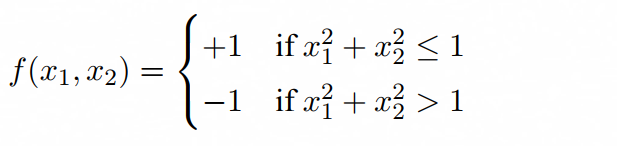
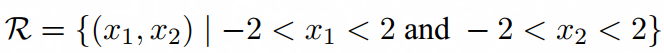

In [4]:
y = []
for i in range(0,N ** 2):
    f = (x[i][0]*x[i][0]) + (x[i][1]*x[i][1])
    if f <= 1:
        y.append(1)
    else:
        y.append(-1)

print(y)

[-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, 1, 1, 1, 1, 1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, 1, 1, 1, 1, 1, 1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, 1, 1, 1, 1, 1, 1, 1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 1, 1, 1, 1, 1, 1, 1, 

In [5]:
y = np.array(y)
print(y.shape, '\t', np.unique(y, return_counts=True))

(441,) 	 (array([-1,  1]), array([364,  77]))


Our ouput has the values of -1 for 1523 inputs and 1 for 77 inputs. Let us plot a graph between the two features of our inputs with the color of the dot based on their output.

Text(0, 0.5, 'xj')

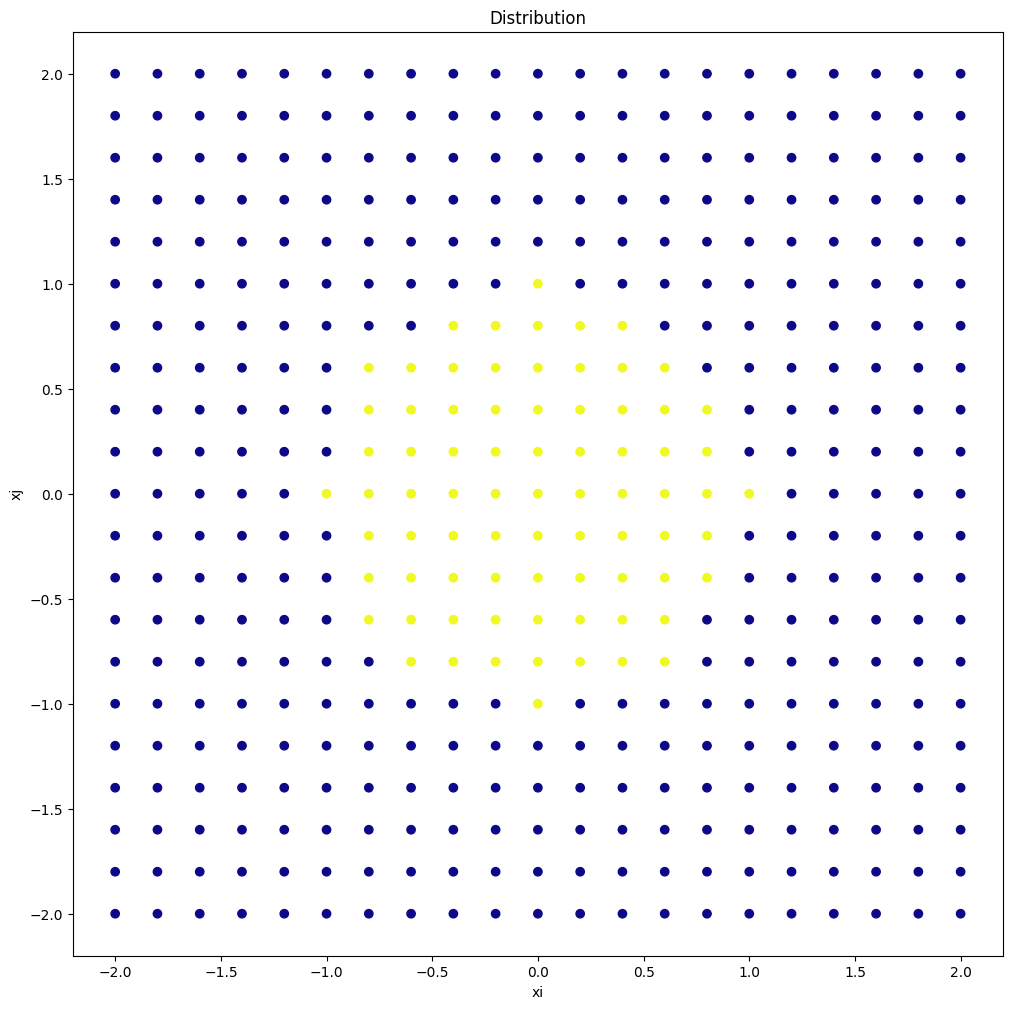

In [6]:
fig, ax = plt.subplots(figsize=(12,12))
ax.scatter(x[:,0], x[:,1], c=y, cmap='plasma')
ax.set_title("Distribution")
ax.set_xlabel("xi")
ax.set_ylabel("xj")

The yellow dots correspond to the output of 1 and the blue to the output of -1.  
Now, we split our dataset into training and test set in a ratio 8:2.

# Split the train data and test data

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

print(X_train.shape, '\t', X_test.shape)
print(y_train.shape, '\t', y_test.shape)

(352, 2) 	 (89, 2)
(352,) 	 (89,)


## Part 2: RBF network class implementation
Since we need to train our RBF network on different parameters, let us define one class that can be reused for all our requirements

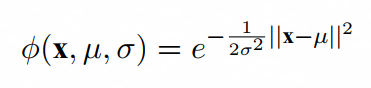

In [8]:
def rbf(x, c, s):
    # radial basis function
    return np.exp(-np.linalg.norm(x - c) ** 2 / (2 * s ** 2))

In [9]:
class RBFN:
    #RBF Network Class
    def __init__(self, num_centres, lr=0.1, epochs=100):
        """Initialization of hyperparameters"""
        self.lr = lr #learning rate
        self.epochs = epochs #number of epochs for training
        #randomly initialise weights
        self.w = np.random.randn(num_centres)
             
    def fit(self, train_ip, train_op, centres, std_dev) -> None:
        """Training phase"""
        self.centres = centres
        self.std_dev = std_dev
        self.mse = []
        
        N = train_ip.shape[0]
        K = centres.shape[0]
        
        Phi = np.zeros((N, K))
        for i in range(N):
            for j in range(K):
                Phi[i, j] = rbf(train_ip[i], centres[j], std_dev)
        
        for epoch in range(self.epochs):
            output = np.dot(Phi, self.w)
            error = train_op - output
            mse_val = np.mean(error**2)
            self.mse.append(mse_val)
            self.w += self.lr * 2 * np.dot(Phi.T, error) / N
            # if epoch % 10 == 0:
            #     print(f"Epoch {epoch}/{self.epochs}, MSE: {mse_val}")

        print(f"Final Training MSE: {self.mse[-1]:.4f}")
      
    def predict(self, test_ip) -> np.array:
        """Prediction of unseen data"""
        N = test_ip.shape[0]
        K = self.centres.shape[0]
        
        Phi_test = np.zeros((N, K))
        for i in range(N):
            for j in range(K):
                Phi_test[i, j] = rbf(test_ip[i], self.centres[j], self.std_dev)
                
        return np.dot(Phi_test, self.w)

The `fit()` function will train our network and store the mean squared error (MSE) at each epoch. Only the final training MSE will be printed to limit the length of the document, but the MSE at each epoch can be printed easily by uncommenting two lines in the function. Alternatively, the object parameter `mse` can be printed for the exact same result.  
The `predict()` function will return the predicted output for the passed input. We use this to calculate the test MSE.

# Part 3: Hyperparameter selection comparison

# Train and Test function

In [ ]:
def train_rbf_network(X_train, y_train, std_range, centres):
    train_mse = []
    test_mse = []
    num_centres = centres.shape[0]
    
    for std in std_range:
        model = RBFN(num_centres=num_centres, lr=0.1, epochs=100)
        model.fit(X_train, y_train, centres, std)
        
        train_mse.append(model.mse[-1])
        
        predictions = model.predict(X_test)
        test_error = y_test - predictions
        test_mse_val = np.mean(test_error**2)
        test_mse.append(test_mse_val)
        
    return train_mse, test_mse

In [11]:
std_range = [0.1,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5]

### Strategy 1: Full training set

Here, the training data itself is passed as the centres to the kernel functions, meaning that we will have 352 neurons in the hidden layer corresponding to 352 Gaussian RBFs with 352 different centres. The standard deviation is kept constant for all functions. We will train 9 networks by varying the spread/standard deviation from 0.1 to 0.5 in steps of 0.05.

In [12]:
# train_test centers assignment
centers = X_train
train_mse, test_mse = train_rbf_network(X_train, y_train, std_range, centres=centers)

Final Training MSE: 1.7182
Final Training MSE: 1.2154
Final Training MSE: 1.0195
Final Training MSE: 0.7221
Final Training MSE: 0.5070
Final Training MSE: 0.3970
Final Training MSE: 0.4914
Final Training MSE: 0.4237
Final Training MSE: 0.2429


Text(0, 0.5, 'Test MSE')

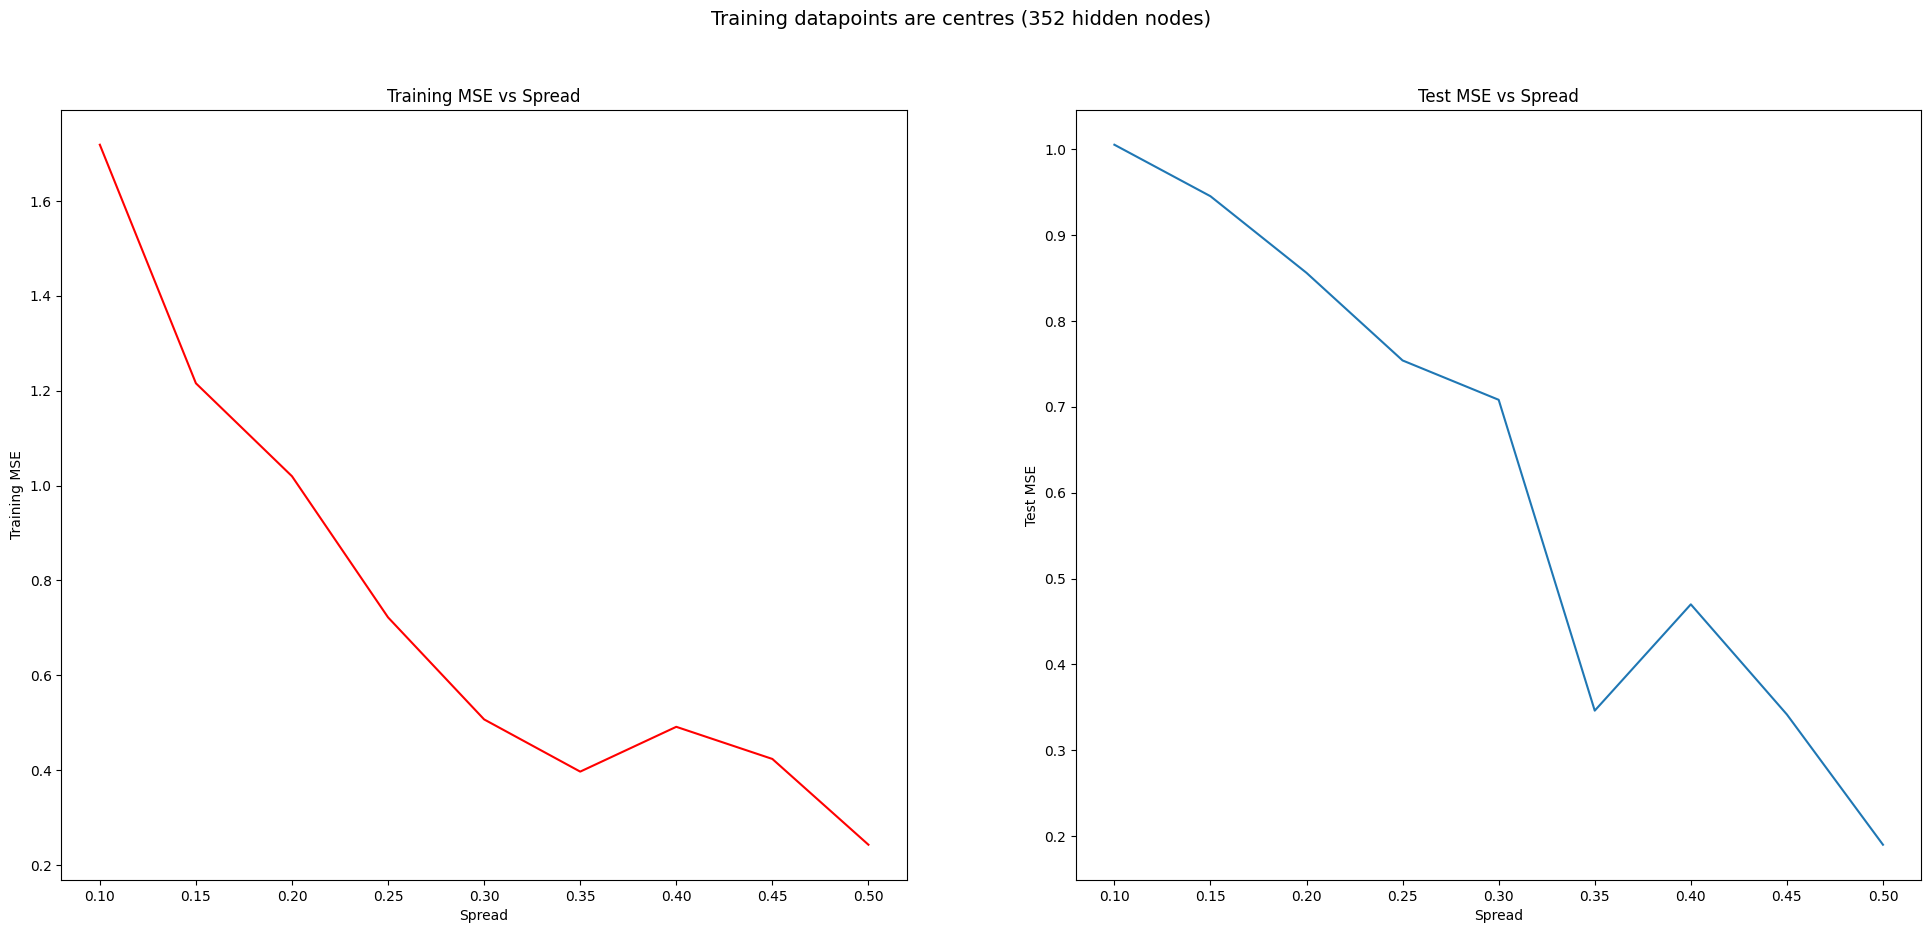

In [13]:
fig, (a1,a2) = plt.subplots(1,2,figsize=(24,10))
fig.suptitle("Training datapoints are centres (352 hidden nodes)", fontsize=14)

a1.plot(std_range, train_mse, c='red')
a1.set_title("Training MSE vs Spread")
a1.set_xlabel("Spread")
a1.set_ylabel("Training MSE")

a2.plot(std_range, test_mse)
a2.set_title("Test MSE vs Spread")
a2.set_xlabel("Spread")
a2.set_ylabel("Test MSE")

### Strategy 2: Random smapling

Here, we need to choose 150 centres for our kernle functions i.e. 150 nodes in the hidden layer. The choice of these is done in 2 different ways.

In [ ]:

indices = np.random.choice(X_train.shape[0], 150, replace=False)
rnd_centers = X_train[indices]
rnd_train_mse, rnd_test_mse = train_rbf_network(X_train, y_train, std_range, centres=rnd_centers)

Final Training MSE: 1.1875
Final Training MSE: 1.2008
Final Training MSE: 1.0562
Final Training MSE: 0.6991
Final Training MSE: 0.4286
Final Training MSE: 0.4218
Final Training MSE: 0.3403
Final Training MSE: 0.3186
Final Training MSE: 0.2427


In [15]:
print("Test MSE across all runs: ", rnd_test_mse)
print()
print( "Minimum Training MSE is {} for a spread of {}".format(min(rnd_train_mse), std_range[np.argmin(rnd_train_mse)]) )
print( "Minimum Test MSE is {} for a spread of {}".format(min(rnd_test_mse), std_range[np.argmin(rnd_test_mse)]) )

Test MSE across all runs:  [np.float64(0.959403720187229), np.float64(0.9256229070382208), np.float64(0.9588318786131905), np.float64(0.7100893231935747), np.float64(0.403481070784594), np.float64(0.4514756937001276), np.float64(0.2280116753668915), np.float64(0.28454319738193057), np.float64(0.204554555404352)]

Minimum Training MSE is 0.2427045119041085 for a spread of 0.5
Minimum Test MSE is 0.204554555404352 for a spread of 0.5


Text(0, 0.5, 'Test MSE')

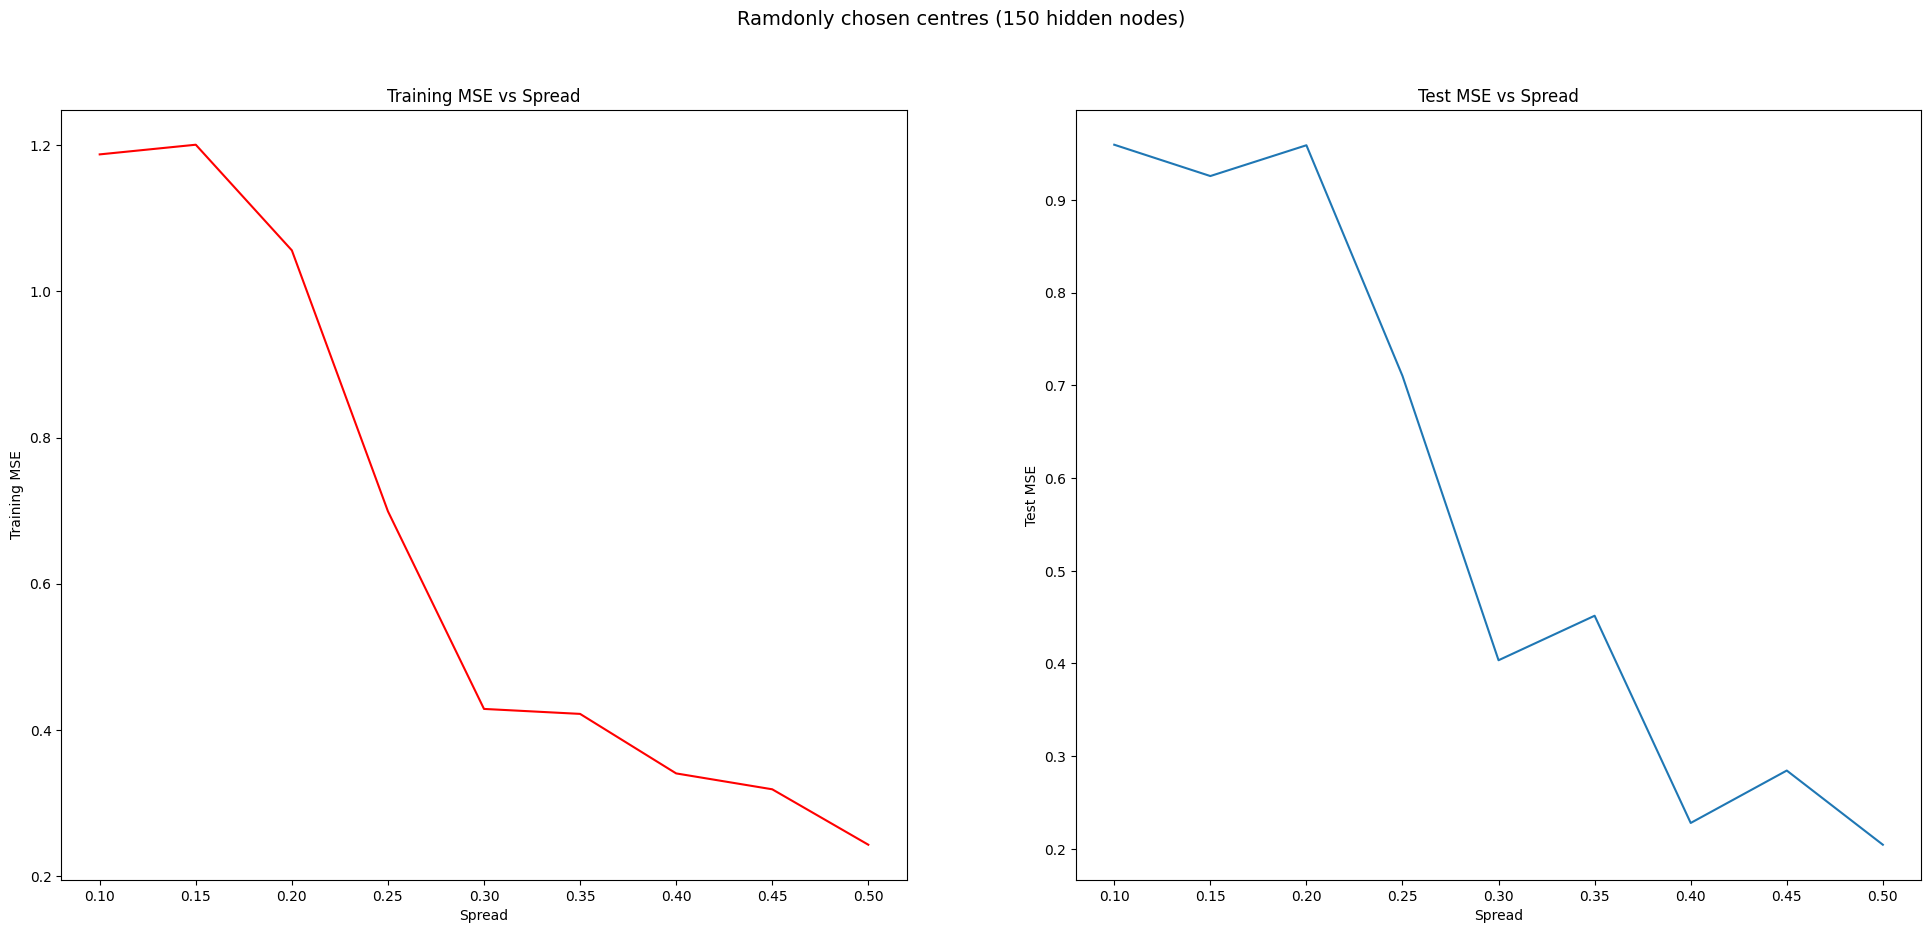

In [16]:
fig, (b1,b2) = plt.subplots(1,2,figsize=(24,10))
fig.suptitle("Ramdonly chosen centres (150 hidden nodes)", fontsize=14)

b1.plot(std_range, rnd_train_mse, c='red')
b1.set_title("Training MSE vs Spread")
b1.set_xlabel("Spread")
b1.set_ylabel("Training MSE")

b2.plot(std_range, rnd_test_mse)
b2.set_title("Test MSE vs Spread")
b2.set_xlabel("Spread")
b2.set_ylabel("Test MSE")

### Strategy 3: K-means clustring

In [17]:
from sklearn.cluster import KMeans

In [18]:
# train_test centers assignment
kmeans = KMeans(n_clusters=150, random_state=0).fit(X_train)
km_centres = kmeans.cluster_centers_
km_train_mse, km_test_mse = train_rbf_network(X_train, y_train, std_range, centres=km_centres)

Final Training MSE: 1.4365
Final Training MSE: 1.2811
Final Training MSE: 1.2726
Final Training MSE: 0.6498
Final Training MSE: 0.6722
Final Training MSE: 0.3678
Final Training MSE: 0.2840
Final Training MSE: 0.3674
Final Training MSE: 0.3441


In [19]:
print("Test MSE across all runs: ", km_test_mse)
print()
print( "Minimum Training MSE is {} for a spread of {}".format(min(km_train_mse), std_range[np.argmin(km_train_mse)]) )
print( "Minimum Test MSE is {} for a spread of {}".format(min(km_test_mse), std_range[np.argmin(km_test_mse)]) )

Test MSE across all runs:  [np.float64(1.0244060885333675), np.float64(0.9539408113613745), np.float64(1.277677151024673), np.float64(0.5109722813930085), np.float64(0.6432930481435813), np.float64(0.3799148783711464), np.float64(0.2792968499203729), np.float64(0.35799414133106183), np.float64(0.3363129007762232)]

Minimum Training MSE is 0.28404748453607875 for a spread of 0.4
Minimum Test MSE is 0.2792968499203729 for a spread of 0.4


Text(0, 0.5, 'Test MSE')

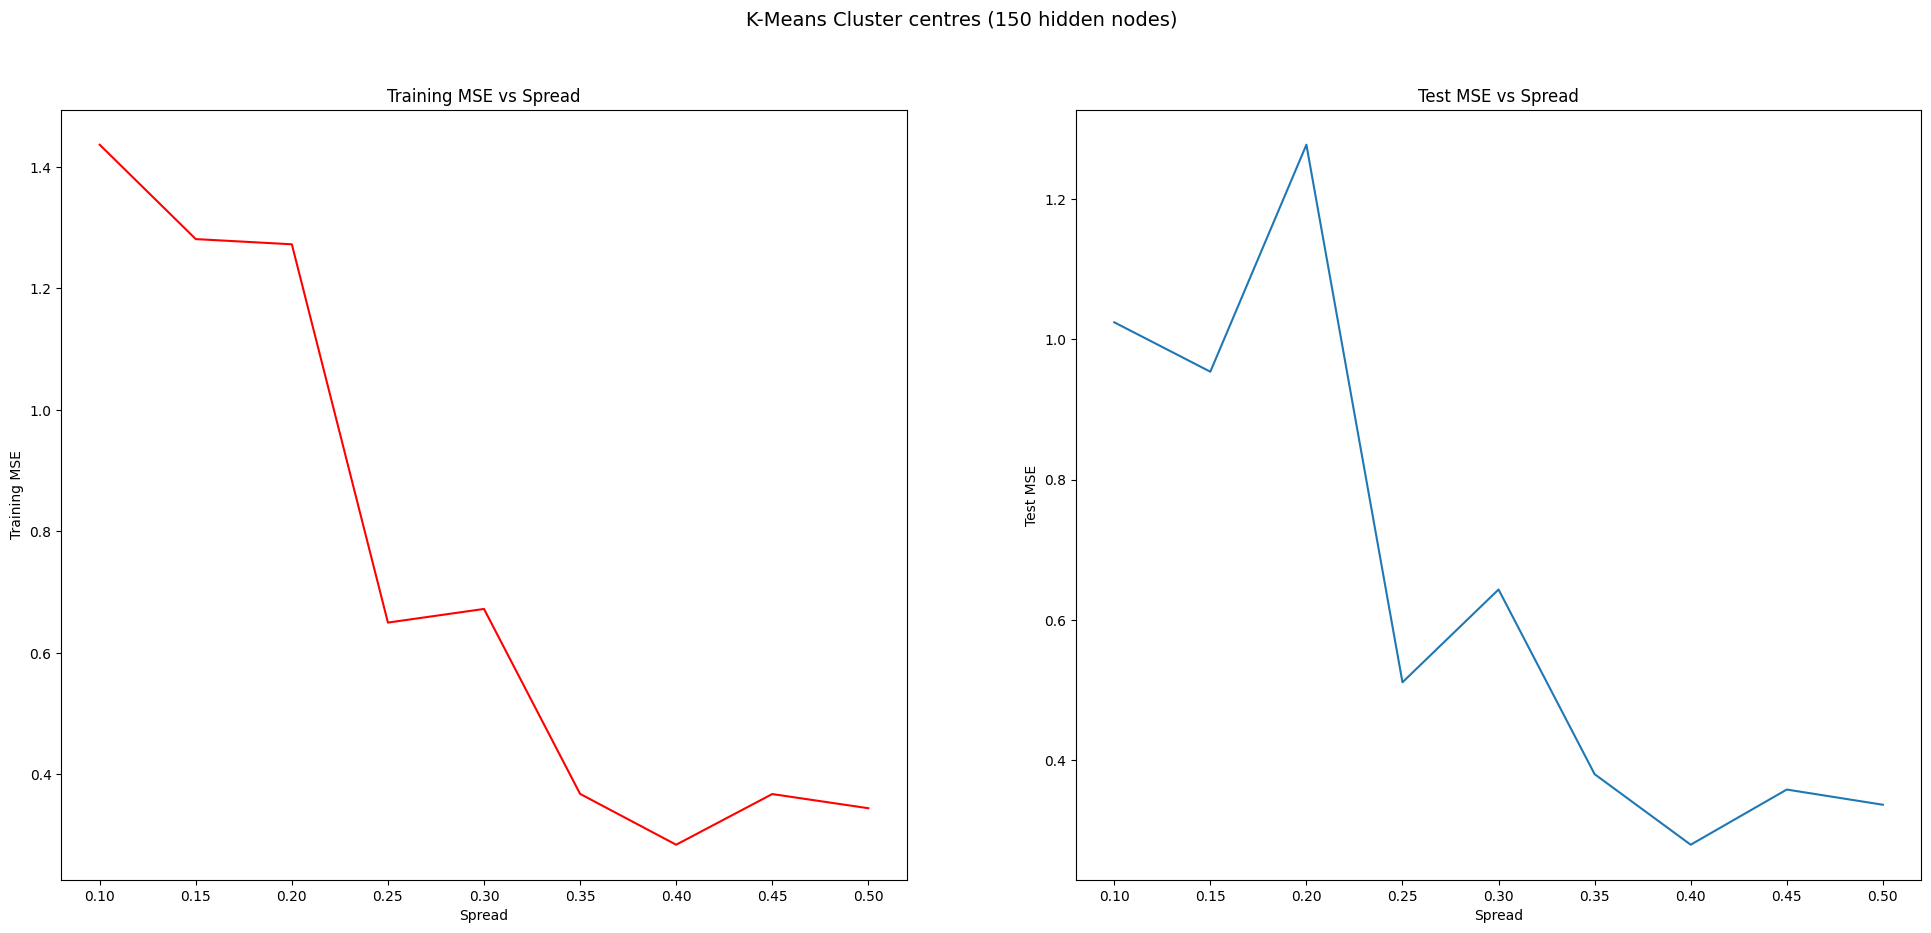

In [20]:
fig, (c1,c2) = plt.subplots(1,2,figsize=(24,10))
fig.suptitle("K-Means Cluster centres (150 hidden nodes)", fontsize=14)

c1.plot(std_range, km_train_mse, c='red')
c1.set_title("Training MSE vs Spread")
c1.set_xlabel("Spread")
c1.set_ylabel("Training MSE")

c2.plot(std_range, km_test_mse)
c2.set_title("Test MSE vs Spread")
c2.set_xlabel("Spread")
c2.set_ylabel("Test MSE")

# Part 4: Result Comparison

Text(0, 0.5, 'Mean Squared Error')

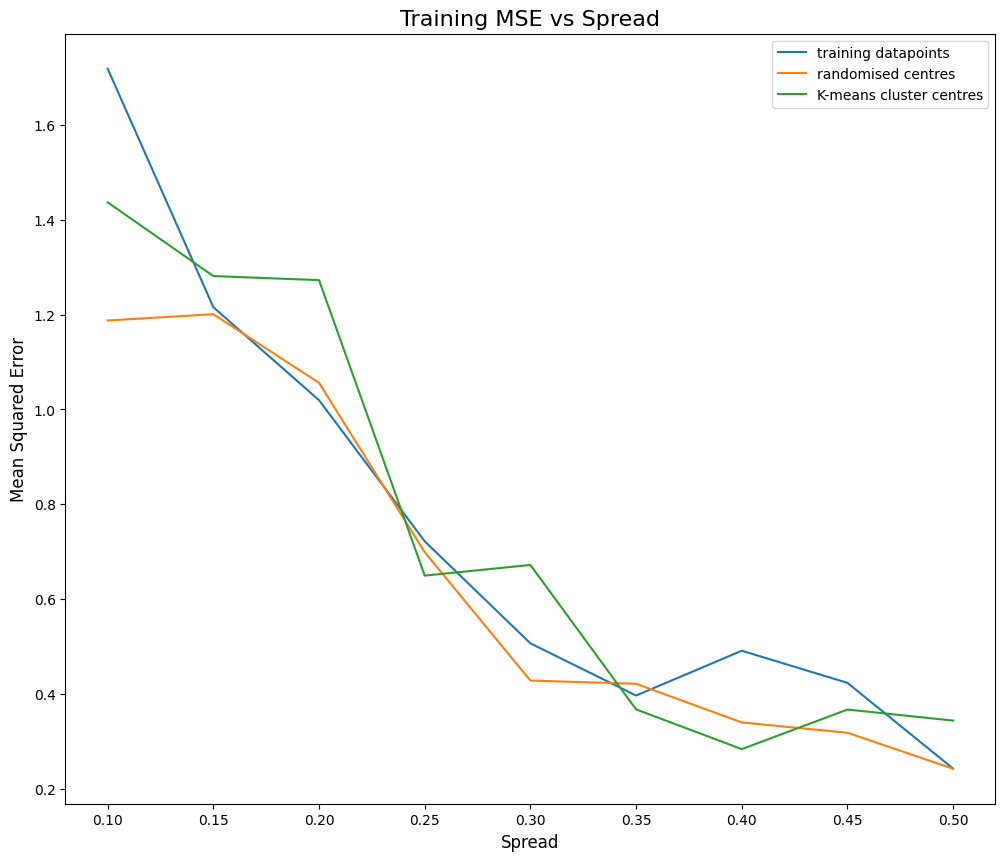

In [21]:
plt.figure(figsize=(12,10))
plt.plot(std_range, train_mse, label="training datapoints")
plt.plot(std_range, rnd_train_mse, label="randomised centres")
plt.plot(std_range, km_train_mse, label="K-means cluster centres")
plt.legend()
plt.title("Training MSE vs Spread", fontsize=16)
plt.xlabel("Spread", fontsize=12)
plt.ylabel("Mean Squared Error", fontsize=12)

Text(0, 0.5, 'Mean Squared Error')

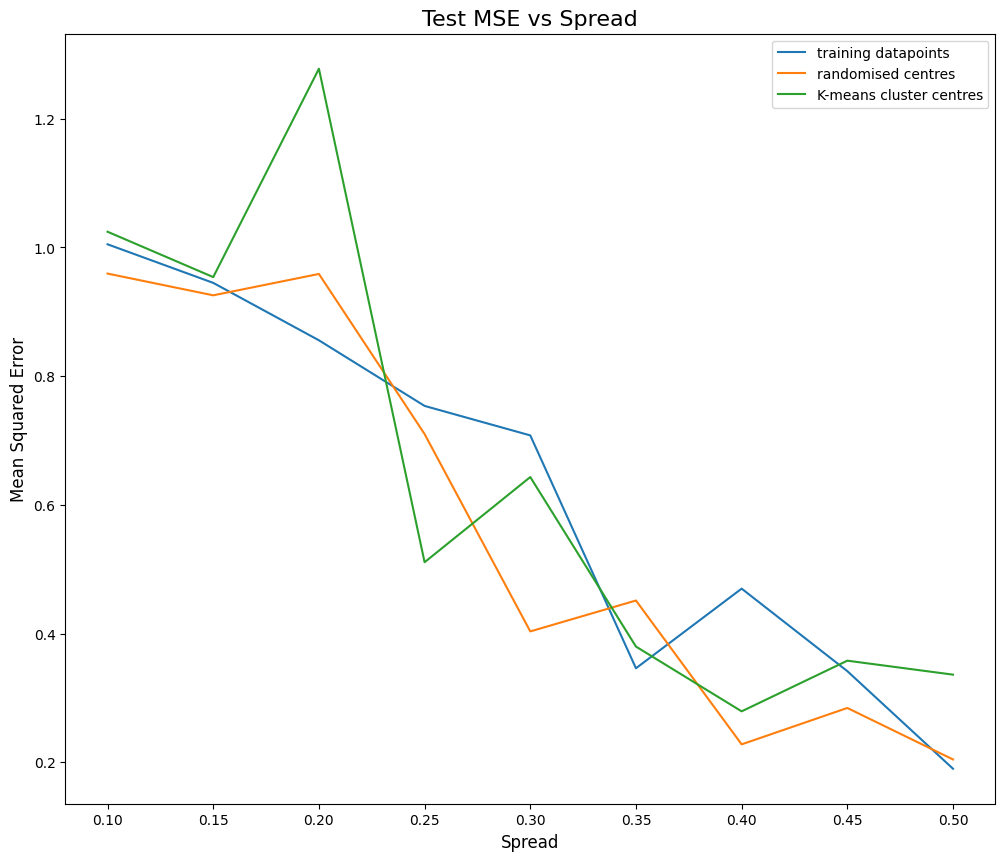

In [22]:
plt.figure(figsize=(12,10))
plt.plot(std_range, test_mse, label="training datapoints")
plt.plot(std_range, rnd_test_mse, label="randomised centres")
plt.plot(std_range, km_test_mse, label="K-means cluster centres")
plt.legend()
plt.title("Test MSE vs Spread", fontsize=16)
plt.xlabel("Spread", fontsize=12)
plt.ylabel("Mean Squared Error", fontsize=12)